In [1]:
from getpass import getpass

import pandas as pd
import numpy as np
import psycopg

consulta = """
SELECT
    station_id, observed_at,
    pm25, pm10, so2, no2, co, o3,
    temp, pres, dewp, rain, wd, wspm
FROM observations
ORDER BY station_id, observed_at
"""

with psycopg.connect(
    host="127.0.0.1",
    port=5432,
    dbname="beijing_pm25",
    user="beijing_app",
    password=getpass("Contraseña de beijing_app: ")
) as conexion:
    with conexion.cursor() as cursor:
        cursor.execute(consulta)
        columnas = [col.name for col in cursor.description]

        bloques = []
        while True:
            filas = cursor.fetchmany(50000)
            if not filas:
                break
            bloques.append(pd.DataFrame(filas, columns=columnas))

datos = pd.concat(bloques, ignore_index=True)

print("Dimensiones:", datos.shape)
print("Estaciones:", datos["station_id"].nunique())
print("Periodo:", datos["observed_at"].min(), "a", datos["observed_at"].max())

datos.head()

Dimensiones: (420768, 14)
Estaciones: 12
Periodo: 2013-03-01 00:00:00 a 2017-02-28 23:00:00


,station_id,observed_at,pm25,pm10,so2,no2,co,o3,temp,pres,dewp,rain,wd,wspm
0,1,2013-03-01 00:00:00,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4
1,1,2013-03-01 01:00:00,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7
2,1,2013-03-01 02:00:00,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6
3,1,2013-03-01 03:00:00,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1
4,1,2013-03-01 04:00:00,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0


In [2]:
datos = datos.sort_values(
    ["station_id", "observed_at"]
).reset_index(drop=True)

grupos = datos.groupby("station_id")

datos["pm25_siguiente"] = grupos["pm25"].shift(-1)
fecha_siguiente = grupos["observed_at"].shift(-1)

hora_consecutiva = fecha_siguiente.eq(
    datos["observed_at"] + pd.Timedelta(hours=1)
)

preparados = datos.loc[
    hora_consecutiva
    & datos["pm25"].notna()
    & datos["pm25_siguiente"].notna()
].copy()

preparados["objetivo_at"] = (
    preparados["observed_at"] + pd.Timedelta(hours=1)
)

preparados["hora"] = preparados["observed_at"].dt.hour
preparados["mes"] = preparados["observed_at"].dt.month
preparados["dia_semana"] = preparados["observed_at"].dt.day_of_week

print("Registros originales:", len(datos))
print("Pares horarios utilizables:", len(preparados))
print("Estaciones:", preparados["station_id"].nunique())

preparados.head()

Registros originales: 420768
Pares horarios utilizables: 409180
Estaciones: 12


,station_id,observed_at,pm25,pm10,so2,no2,co,o3,temp,pres,dewp,rain,wd,wspm,pm25_siguiente,objetivo_at,hora,mes,dia_semana
0,1,2013-03-01 00:00:00,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,8.0,2013-03-01 01:00:00,0,3,4
1,1,2013-03-01 01:00:00,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,7.0,2013-03-01 02:00:00,1,3,4
2,1,2013-03-01 02:00:00,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,6.0,2013-03-01 03:00:00,2,3,4
3,1,2013-03-01 03:00:00,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,3.0,2013-03-01 04:00:00,3,3,4
4,1,2013-03-01 04:00:00,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,5.0,2013-03-01 05:00:00,4,3,4


In [3]:
horas = np.sort(preparados["objetivo_at"].unique())

corte_train = horas[int(len(horas) * 0.70)]
corte_val = horas[int(len(horas) * 0.85)]

train = preparados.loc[
    preparados["objetivo_at"] < corte_train
].copy()

val = preparados.loc[
    (preparados["objetivo_at"] >= corte_train)
    & (preparados["objetivo_at"] < corte_val)
].copy()

test = preparados.loc[
    preparados["objetivo_at"] >= corte_val
].copy()

for nombre, conjunto in [
    ("Entrenamiento", train),
    ("Validación", val),
    ("Prueba", test)
]:
    print(
        nombre,
        len(conjunto),
        conjunto["objetivo_at"].min(),
        conjunto["objetivo_at"].max()
    )

Entrenamiento 286357 2013-03-01 01:00:00 2015-12-17 21:00:00
Validación 61262 2015-12-17 22:00:00 2016-07-24 00:00:00
Prueba 61561 2016-07-24 01:00:00 2017-02-28 23:00:00


In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_real = val["pm25_siguiente"]
y_predicho = val["pm25"]

mae = mean_absolute_error(y_real, y_predicho)
rmse = np.sqrt(mean_squared_error(y_real, y_predicho))

print("Baseline de persistencia")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

Baseline de persistencia
MAE: 10.1409
RMSE: 20.1472


In [5]:
variables = [
    "pm25", "pm10", "so2", "no2", "co", "o3",
    "temp", "pres", "dewp", "rain", "wd", "wspm"
]

faltantes = (
    train[variables]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .round(2)
)

print("Porcentaje de valores faltantes en entrenamiento:")
print(faltantes)

Porcentaje de valores faltantes en entrenamiento:
co      4.82
o3      2.19
no2     1.94
so2     1.04
wd      0.21
dewp    0.06
pres    0.06
temp    0.06
pm10    0.06
wspm    0.06
rain    0.06
pm25    0.00
dtype: float64


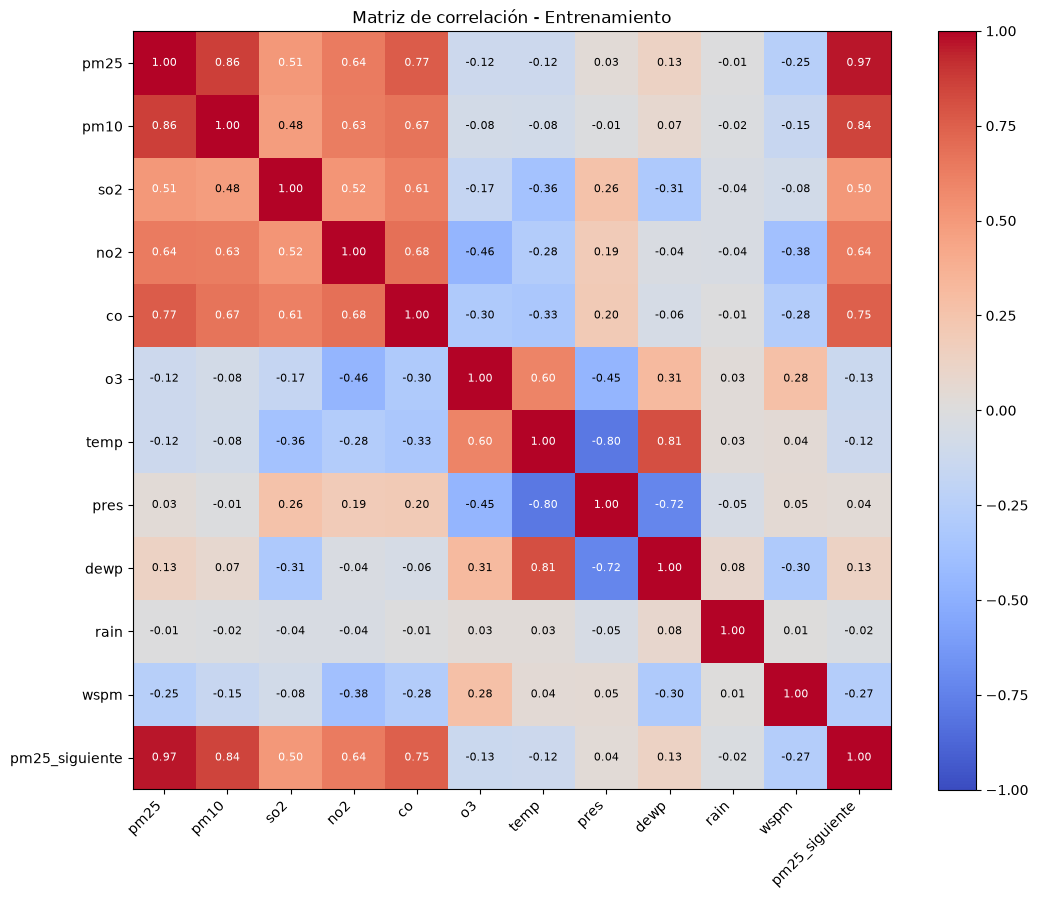

Correlación con PM2.5 de la siguiente hora:


pm25    0.967
pm10    0.844
co      0.749
no2     0.636
so2     0.500
wspm   -0.271
o3     -0.127
dewp    0.127
temp   -0.124
pres    0.035
rain   -0.025
Name: pm25_siguiente, dtype: float64

In [6]:

import matplotlib.pyplot as plt

columnas = [
    "pm25", "pm10", "so2", "no2", "co", "o3",
    "temp", "pres", "dewp", "rain", "wspm",
    "pm25_siguiente"
]

correlacion = train[columnas].corr()

fig, ax = plt.subplots(figsize=(11, 9))
imagen = ax.imshow(correlacion, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(columnas)))
ax.set_yticks(range(len(columnas)))
ax.set_xticklabels(columnas, rotation=45, ha="right")
ax.set_yticklabels(columnas)

for i in range(len(columnas)):
    for j in range(len(columnas)):
        valor = correlacion.iloc[i, j]
        ax.text(
            j, i, f"{valor:.2f}",
            ha="center", va="center",
            fontsize=8,
            color="white" if abs(valor) > 0.5 else "black"
        )

fig.colorbar(imagen, ax=ax)
ax.set_title("Matriz de correlación - Entrenamiento")
plt.tight_layout()
plt.show()

print("Correlación con PM2.5 de la siguiente hora:")
display(
    correlacion["pm25_siguiente"]
    .drop("pm25_siguiente")
    .sort_values(key=lambda x: x.abs(), ascending=False)
    .round(3)
)


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor

numericas = [
    "pm25", "pm10", "so2", "no2", "co", "o3",
    "temp", "pres", "dewp", "rain", "wspm",
    "hora", "mes", "dia_semana"
]

categoricas = ["station_id", "wd"]
columnas_modelo = numericas + categoricas

def preparar_entradas(conjunto):
    X = conjunto[columnas_modelo].copy()
    X["station_id"] = X["station_id"].astype(str)
    X["wd"] = X["wd"].fillna("Desconocido").astype(str)
    return X

X_train = preparar_entradas(train)
X_val = preparar_entradas(val)

y_train = train["pm25_siguiente"]
y_val = val["pm25_siguiente"]

preprocesador = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), numericas),
    ("categoricas", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categoricas)
])

modelo = Pipeline([
    ("preprocesador", preprocesador),
    ("regresor", HistGradientBoostingRegressor(
        max_iter=120,
        learning_rate=0.08,
        max_leaf_nodes=31,
        early_stopping=False,
        random_state=42
    ))
])

modelo.fit(X_train, y_train)

print("Modelo entrenado correctamente")
print("Registros utilizados:", len(X_train))
print("Variables originales:", len(columnas_modelo))

Modelo entrenado correctamente
Registros utilizados: 286357
Variables originales: 16


In [8]:
from sklearn.metrics import r2_score

predicciones = modelo.predict(X_val)

mae_modelo = mean_absolute_error(y_val, predicciones)
rmse_modelo = np.sqrt(mean_squared_error(y_val, predicciones))
r2_modelo = r2_score(y_val, predicciones)

print("Comparación en validación")
print(f"MAE persistencia: {mae:.4f}")
print(f"MAE modelo:       {mae_modelo:.4f}")

print(f"RMSE persistencia: {rmse:.4f}")
print(f"RMSE modelo:       {rmse_modelo:.4f}")

print(f"R² modelo: {r2_modelo:.4f}")
print("Predicciones negativas:", (predicciones < 0).sum())

print(
    f"Variación MAE respecto al baseline: "
    f"{100 * (mae - mae_modelo) / mae:.2f}%"
)

Comparación en validación
MAE persistencia: 10.1409
MAE modelo:       10.0319
RMSE persistencia: 20.1472
RMSE modelo:       21.1244
R² modelo: 0.9333
Predicciones negativas: 0
Variación MAE respecto al baseline: 1.07%
